# Sequential Learning of Active Subspaces: the Minnesota COVID-19 model

__Nathan Wycoff__, Mathematics and Computer Science Division, Argonne National Laboratory, Lemont, IL (current institution: Department of Statistics, Virginia Tech, Blacksburg, VA)

__Mickaël Binois__, Mathematics and Computer Science Division, Argonne National Laboratory, Lemont, IL (current institution: Université Côte d'Azur, Inria, CNRS, LJAD, France)

__Stefan M. Wild__, Mathematics and Computer Science Division, Argonne National Laboratory, Lemont, IL

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies the third example of [[1]][R1] (Sec. 4.3), the University of Minnesota COVID-19 model [[2]][R2] run as a black box with eight uncertain inputs and the cumulative number of deaths over one year as the output. The model is R code from the article's supplement; the data here were generated by running that code with R. The notebook needs only numpy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1.0 or later), and takes about 10 s.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import mn_covid_driver as mn

SEED = 2021                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = mn.SHORT
qlabel = 'deaths at day 365'


def order(v):
    """Order of magnitude of a rounding-level value (4.7e-13 -> '1e-13'); such values change between platforms."""
    return f'1e{int(np.floor(np.log10(abs(v))))}' if v != 0 else '0'

### Summary

Wycoff, Binois and Wild [[1]][R1] estimate the active subspace of a Gaussian-process surrogate in closed form, use it to choose model runs sequentially, and test the method on the Minnesota COVID-19 model, for which they report a three-dimensional active subspace from a Gaussian process fitted to 2,000 random runs. We ran the same R model from the article's supplement at 100 Monte Carlo samples of its eight inputs, with forward-difference gradients (900 runs), and estimate the active subspace of cumulative deaths directly from the gradients. The eigenvalues drop by a factor of 352 after the third ($\lambda_1/\lambda_2 = 9.04$, $\lambda_2/\lambda_3 = 3.34$), the three active directions lie almost entirely in the span of the proportion of asymptomatic infections and the hospitalization and home-death probabilities of the oldest groups, and the three-dimensional subspace is within a distance of 0.0152 of the one in the article's own reference matrix, whose choice of three dimensions it confirms.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

The Minnesota COVID-19 model [[2]][R2] is a discrete-time compartmental model of the epidemic in Minnesota, structured by nine age groups $a$ (0–9, 10–19, …, 70–79, 80+) and two comorbidity groups $c$ (none, at least one). The article treats it as a black box (Sec. 4.3, p. 24); the description below is of the code the article ran, `covid_allinone.R` in its supplement (`code.zip`, [figshare](https://doi.org/10.6084/m9.figshare.13611284)). Each age and comorbidity group has the compartments $S$ (susceptible), $E_1, E_2$ (exposed), $A_1..A_3$ (asymptomatic or mild infection), $I_1..I_3$ (symptomatic infection), $H$ (hospital), $ICU$, $R$ (recovered) and $D$ (dead). The state is advanced from day 1 to day 365 in steps of $\Delta t = 0.05$ day by

$$
\mathbf u_{k+1} = \mathbf u_k + \Delta\mathbf u(t_k, \mathbf u_k),
$$

where each increment moves people between compartments with per-step probabilities $1 - e^{-r\Delta t}$ (rate $r$ per day). New infections in group $a$ are $\beta\,\lambda_a\,S_a$ per step, with $\beta = 0.0295$ and force of infection $\lambda_a = \Delta t\sum_b M_{ab}\,(A_b + I_b)/(N_b - D_b)$ from a Minnesota contact matrix $M$ (contacts per day). Exposed people pass through $E_1, E_2$ at rate $2/5.2$ per day; a fraction $x_6$ (`prop_asymptomatic`) enters the $A$ chain and $1 - x_6$ the $I$ chain, both traversed at rate $3/7.8$ per day. On leaving $I_3$, a fraction $h_a = \eta_a x_7$ is hospitalized ($\eta_a$ rises from 0.018 for ages 0–9 to 1 for ages 80+, so $x_7$ = `p_h_80` is the probability for ages 80+), split between $H$ and $ICU$; of the others, a fraction $x_8$ (`p_dying_home_80`) of those aged 70 or more die at home (the code applies $x_8$ to ages 70–79 and 80+; footnote 4, p. 24, calls it the probability of a person over 80 dying at home) and the rest recover. $H$ and $ICU$ are left at rates $1/11$ and $1/8$ per day, with age-dependent death probabilities. When ICU demand exceeds 2,200 beds, the overflow leaves the ICU after one day and dies. Everyone in $A$ recovers.

The article's simulator is the code's "scenario 2" (`covid_sim` in `covid_allinone.R`): social distancing multiplies the contact matrix by $1 - x_3$ for $1 \le t < 41$, and shelter in place, which takes precedence, by $1 - x_2$ for $6 \le t < 20$. The initial state has the 233 cases detected in Minnesota on 23 March 2020 (in $I_3$, $H$ and $ICU$) plus $233\,(1 - x_1)/x_1$ undetected infections spread over $E$, $A$ and $I$, where $x_1$ is the fraction of cases detected. **The quantity of interest** is the cumulative number of deaths, $\sum_{a,c} D_{a,c}$, at $t = 365$.

The inputs are the eight arguments of `covid_sim`. The article lists them in footnote 4 (p. 24) as seven items, naming the shelter-in-place and social-distancing contact reductions together; the code and the eight eigenvalues of the article's Fig. 5 (p. 25) have eight. Their ranges are not stated in the article. The article's study script `covid_sim.R` maps the unit cube to $[0.01, 0.99]^8$ by $x = 0.98\,u + 0.01$, and we use that box, with every input independent and uniform (this data set's design; the article's 2,000-run reference fit, `covid_est_C.R`, sampled the unit cube $[0, 1]^8$ itself). In scenario 2 the start times of the targeted 60+ distancing and of the lasting behaviour change are infinite, so **inputs 4 and 5 never enter the computation** and the output does not depend on them.

In [2]:
print(f"{'':2s} {'input (code name)':37s} {'units':12s} {'code default':>12s} {'range':>14s}  description")
for j, n in enumerate(mn.NAMES):
    print(f'x{j + 1} {n:37s} {mn.UNITS[j]:12s} {mn.NOMINAL[j]:12.7g} [{mn.LOWER[j]:.2f}, {mn.UPPER[j]:.2f}]  {mn.DESCRIPTIONS[j]}')
print(f'\nundetected initial infections 233 (1 - x1)/x1: {233 * (1 - mn.UPPER[0]) / mn.UPPER[0]:.2f} at x1 = 0.99, '
      f'{233 * (1 - mn.LOWER[0]) / mn.LOWER[0]:.0f} at x1 = 0.01')

   input (code name)                     units        code default          range  description
x1 init_cases_detected                   fraction       0.02143008 [0.01, 0.99]  fraction of cases detected at day 0
x2 sip_contact_reduction                 fraction        0.5511887 [0.01, 0.99]  contact reduction, shelter in place
x3 social_distancing_contact_reduction   fraction        0.3755247 [0.01, 0.99]  contact reduction, social distancing
x4 sixty_plus_contact_reduction          fraction              0.5 [0.01, 0.99]  contact reduction, people aged 60+
x5 behavior_change_contact_reduction     fraction              0.1 [0.01, 0.99]  contact reduction, behaviour change
x6 prop_asymptomatic                     fraction        0.4116304 [0.01, 0.99]  proportion asymptomatic or mild
x7 p_h_80                                probability     0.1032184 [0.01, 0.99]  P(hospitalized | symptomatic, age 80+)
x8 p_dying_home_80                       probability     0.1392806 [0.01, 0.99]  P(deat

Sources: the names, the code defaults and the roles are those of `parameters()` and `covid_sim()` in `covid_allinone.R` (the defaults of $x_1, x_2, x_3, x_6, x_7, x_8$ are marked there "calibrated value 5/11/2020"); the range is the map of `covid_sim.R`; the article's names are in footnote 4, p. 24. The code default of $x_1$, 0.0214, lies near the lower end of the range, so most of the box describes far fewer undetected initial infections than the calibrated model.

### Load data

`generate_data.py` drew $M = 100$ Monte Carlo samples (seed 2021), ran the R model at each sample and at the eight points $\mathbf x + h\,\mathbf e_j$ with $h = 10^{-7}$, and wrote the inputs, the deaths and the forward-difference gradients (deaths per unit of each input). It needs R and the article's supplement; the 900 runs took about 2 h of wall time on a shared 2-core machine (about 3 s of CPU per run) (see `DATA.md`). This notebook only reads the files.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')        # (M, 8) inputs, code units (fractions)
f = np.loadtxt('outputs.csv', delimiter=',')       # (M,) cumulative deaths at day 365
G = np.loadtxt('gradients.csv', delimiter=',')     # (M, 8) d deaths / d x_j
print(f'inputs {X.shape}, outputs {f.shape}, gradients {G.shape}')

inputs (100, 8), outputs (100,), gradients (100, 8)


Checks of the files: the inputs fill the box and are uniform; the gradient columns of inputs 4 and 5 are exactly zero (the code never reads those inputs); and the least-squares slope of the deaths on the normalized inputs points the same way as the mean normalized gradient, which confirms the gradient coordinates.

In [4]:
space = ac.Uniform(mn.LOWER, mn.UPPER, names=mn.NAMES)
XN = space.to_normalized(X)
GN = G * (mn.UPPER - mn.LOWER) / 2                 # gradients in normalized coordinates (for the checks only)
kurt = ((XN - XN.mean(0))**4).mean(0) / XN.var(0)**2
print(f'normalized inputs in [{XN.min():.3f}, {XN.max():.3f}]; kurtosis per input {np.array2string(kurt, precision=2)} (uniform: 1.8)')
print(f'duplicate rows: {len(X) - len(np.unique(X, axis=0))}')
print(f'gradient columns 4 and 5: number of nonzero entries {np.count_nonzero(G[:, mn.INACTIVE])}')
print(f'deaths in [{f.min():.0f}, {f.max():.0f}], mean {f.mean():.0f}, median {np.median(f):.0f}')
A = np.column_stack([np.ones(len(f)), XN])
slope = np.linalg.lstsq(A, f, rcond=None)[0][1:]
gbar = GN.mean(0)
print(f'cosine(least-squares slope, mean normalized gradient) = {slope @ gbar / np.linalg.norm(slope) / np.linalg.norm(gbar):.4f}')
print(f'normalized gradient norms: median {np.median(np.linalg.norm(GN, axis=1)):.4g}, '
      f'range [{np.linalg.norm(GN, axis=1).min():.4g}, {np.linalg.norm(GN, axis=1).max():.4g}]')

normalized inputs in [-0.998, 0.998]; kurtosis per input [1.83 1.91 1.7  1.73 1.72 1.87 1.73 1.75] (uniform: 1.8)
duplicate rows: 0
gradient columns 4 and 5: number of nonzero entries 0
deaths in [1416, 452182], mean 174834, median 170423
cosine(least-squares slope, mean normalized gradient) = 0.9905
normalized gradient norms: median 2.201e+05, range [2.832e+04, 3.092e+05]


The 100 samples fill the box (normalized inputs from $-0.998$ to $0.998$, kurtosis 1.70–1.91 against 1.8 for a uniform variable) with no duplicate rows. The gradient columns of $x_4$ and $x_5$ have no nonzero entry. The deaths range from 1,416 to 452,182 (median 170,423): the box runs from almost no symptomatic infections to almost all, so it covers epidemics of very different severity. The cosine between the least-squares slope and the mean normalized gradient is 0.9905.

### Estimate the subspace

The gradients are forward differences of a deterministic double-precision code with a step of $10^{-7}$; `check_accuracy.py` finds them within $1.5\times10^{-8}$ to $6.1\times10^{-8}$ (relative 2-norm error at three rows) of central differences (DATA.md, Accuracy). We therefore use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates, with $M = 100$ and 500 bootstrap replicates. The input space is `ac.Uniform` on the box above, so every input is scaled by its own half-range, 0.49, to $[-1, 1]$. The paper publishes no eigenvectors, so the signs follow the eigenvectors of the article's own reference matrix (below), whose largest entry we take positive (`ac.orient(by="reference")`).

In [5]:
# The article's reference matrix C (code/data/covid_Ch.RData, object Cbmat: GP estimate from 2,000 uniform runs on
# [0, 1]^8); eigenvalues and first three eigenvectors as printed by check_accuracy.py (sign: largest entry positive).
paper_lam = np.array([161709932994, 17105920150, 3926255212, 47997853, 8001484, 7249267, 6998373, 5256167], float)
paper_W = np.array([[-0.0049521714, -0.0004217219, -0.0003955072,  0.0000705922, -0.0006062329,  0.8863572836, -0.3547220014, -0.2975194728],
                    [-0.0014862101, -0.0008376842,  0.0025716949,  0.0012750630,  0.0028581200,  0.4627056551,  0.6569469958,  0.5952350819],
                    [-0.0082975305, -0.0001885872,  0.0051597625, -0.0021063867,  0.0048966381, -0.0157369061, -0.6652400667,  0.7463806548]]).T

sub = ac.active_subspace(space=space, X=X, f=f, grads=G, estimator='as', nboot=500, rng=SEED)
ref = np.column_stack([paper_W, np.zeros((8, 5))])
sub = ac.orient(sub, by='reference', reference=ref, columns=3)
lam = sub.eigenvalues
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
N_CHOSEN = 3                      # the dimension used below (justified in the text after the next figures)
sub = ac.with_dimension(sub, N_CHOSEN)
tol = len(lam) * np.finfo(float).eps * lam[0]
k0 = int(np.sum(np.abs(lam) > tol))
print('eigenvalues ' + np.array2string(lam[:k0], precision=4))
for k in range(k0, len(lam)):
    print(f'lambda_{k + 1} is numerically zero (of order {order(lam[k])} in this run; round-off level m eps lambda_1 = {tol:.0e})')
print('ratios lambda_k/lambda_k+1 ' + np.array2string(lam[:k0 - 1] / lam[1:k0], precision=3))
print(f'eigenvalue-gap rule: n = {k_hat}')
print(f'share of sum(lambda) beyond k = 1, 2, 3: ' + ', '.join(f'{lam[k:].sum() / lam.sum():.2e}' for k in (1, 2, 3)))

eigenvalues [3.9554e+10 4.3757e+09 1.3098e+09 3.7216e+06 4.4481e+04 1.3491e+04]
lambda_7 is numerically zero (of order 1e-26 in this run; round-off level m eps lambda_1 = 7e-05)
lambda_8 is numerically zero (of order 1e-28 in this run; round-off level m eps lambda_1 = 7e-05)
ratios lambda_k/lambda_k+1 [  9.04    3.341 351.948  83.666   3.297]
eigenvalue-gap rule: n = 1
share of sum(lambda) beyond k = 1, 2, 3: 1.26e-01, 2.90e-02, 8.35e-05


### Results

**Eigenvalues.** The figure shows the eigenvalues with 95 % bootstrap bands (the two eigenvalues of the null space of inputs 4 and 5, which are at rounding level, are not drawn).

lambda_1/lambda_2: estimate 9.04, bootstrap 2.5-97.5 % [7.08, 12]
lambda_2/lambda_3: estimate 3.34, bootstrap 2.5-97.5 % [1.78, 6.65]
lambda_3/lambda_4: estimate 352, bootstrap 2.5-97.5 % [117, 3.84e+03]


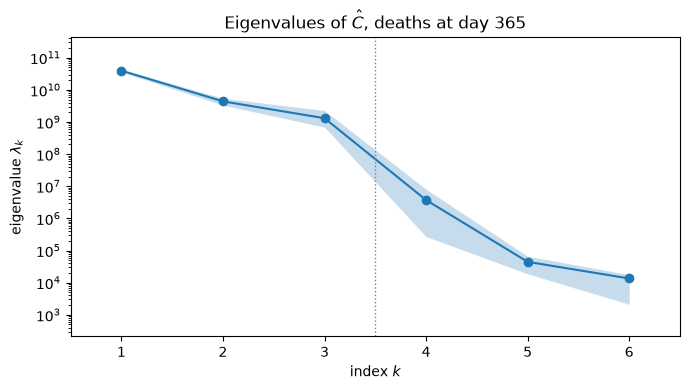

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ac.plotting.plot_eigenvalues(sub, ax=ax, k_max=k0)
ax.set_title('Eigenvalues of $\\hat{C}$, ' + qlabel)
fig.tight_layout()
plt.close(fig)
b = sub.bootstrap_eigenvalues
for k in range(3):
    print(f'lambda_{k + 1}/lambda_{k + 2}: estimate {lam[k] / lam[k + 1]:.3g}, bootstrap 2.5-97.5 % '
          f'[{np.percentile(b[:, k] / b[:, k + 1], 2.5):.3g}, {np.percentile(b[:, k] / b[:, k + 1], 97.5):.3g}]')
fig

The eigenvalues are $\lambda_1 = 3.955\times10^{10}$, $\lambda_2 = 4.376\times10^{9}$, $\lambda_3 = 1.310\times10^{9}$ and $\lambda_4 = 3.72\times10^{6}$, then $4.45\times10^{4}$ and $1.35\times10^{4}$. $\mathbf C$ has a two-dimensional null space (the gradient columns of $x_4$ and $x_5$ are zero), and the computed $\lambda_7$ and $\lambda_8$ are at rounding level (of order $10^{-26}$ and $10^{-28}$ in this run, below the round-off level $7\times10^{-5}$): they belong to $x_4$ and $x_5$, which the output does not depend on. The ratios and their 95 % bootstrap intervals are $\lambda_1/\lambda_2 = 9.04$ [7.08, 12], $\lambda_2/\lambda_3 = 3.34$ [1.78, 6.65] and $\lambda_3/\lambda_4 = 352$ [117, 3840]. The library's eigenvalue-gap rule picks $n = 1$ (the largest absolute gap). **We use $n = 3$**: $\lambda_3/\lambda_4$ is by far the largest ratio, with a lower bootstrap bound of 117; the eigenvalues beyond the third carry $8.35\times10^{-5}$ of their sum, against $2.90\times10^{-2}$ beyond the second and 0.126 beyond the first; and the surrogates below need three active variables. The ratio $\lambda_2/\lambda_3 = 3.34$ is small, so a two-dimensional summary is a reasonable but coarser approximation.

bootstrap mean subspace distance: n = 1: 0.0385, n = 2: 0.0542, n = 3: 0.00616, n = 4: 0.0412, n = 5: 0.127


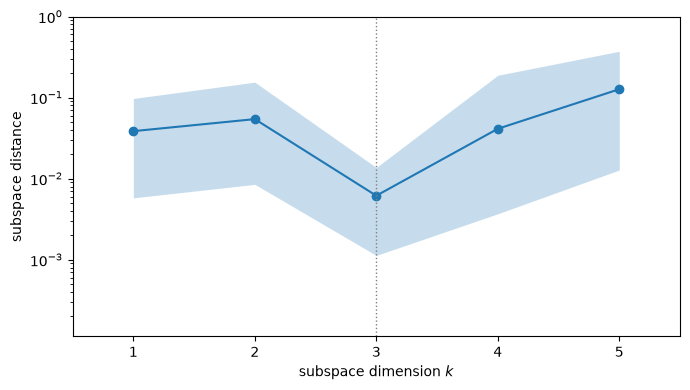

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ac.plotting.plot_subspace_errors(sub, ax=ax, k_max=k0 - 1)
fig.tight_layout()
plt.close(fig)
dist = sub.bootstrap_distances.mean(axis=0)
print('bootstrap mean subspace distance: ' + ', '.join(f'n = {k + 1}: {d:.3g}' for k, d in enumerate(dist[:k0 - 1])))
fig

The bootstrap mean subspace distance is 0.0385 for $n = 1$, 0.0542 for $n = 2$ and 0.00616 for $n = 3$: the three-dimensional subspace is the best determined of all, as the large gap after $\lambda_3$ predicts.

w1 = [-0.0035 -0.0007 -0.0001  0.      0.      0.8743 -0.3572 -0.3286]
w2 = [-0.0029 -0.     -0.0006  0.      0.      0.4849  0.6152  0.6216]
w3 = [ 0.005   0.0012  0.0003  0.     -0.     -0.0198 -0.7028  0.711 ]
w4 = [ 0.9959  0.075   0.0496 -0.      0.      0.0046  0.0041 -0.003 ]
activity scores (n = 3), normalized: [0.     0.     0.     0.     0.     0.6911 0.1624 0.1464]


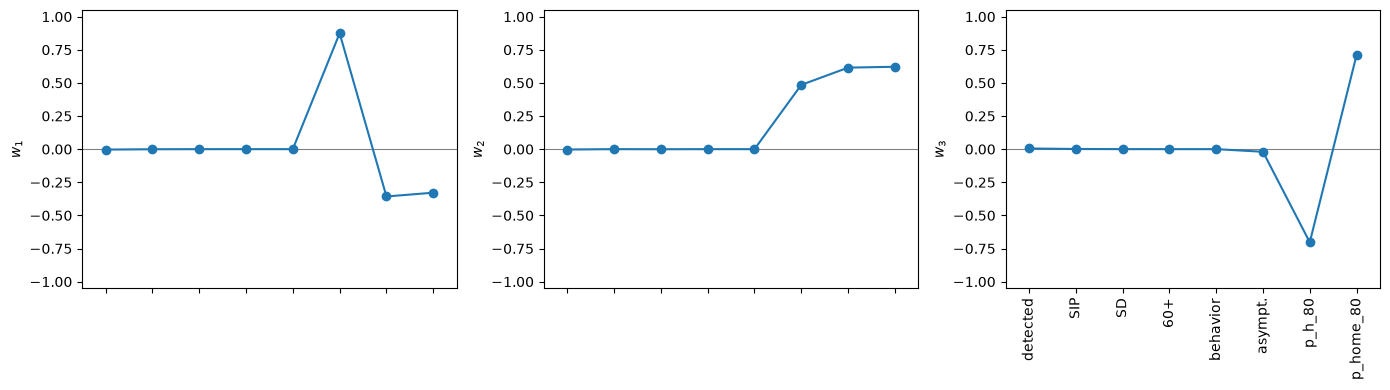

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ac.plotting.plot_eigenvectors(sub, indices=[0, 1, 2], labels=labels, ax=list(axes))
fig.tight_layout()
plt.close(fig)
for k in range(4):
    print(f'w{k + 1} = ' + np.array2string(sub.W[:, k], precision=4, suppress_small=True))
alpha = ac.activity_scores(sub, n=3)
print('activity scores (n = 3), normalized: ' + np.array2string(alpha / alpha.sum(), precision=4, suppress_small=True))
fig

The first three eigenvectors live on $x_6$ (`prop_asymptomatic`), $x_7$ (`p_h_80`) and $x_8$ (`p_dying_home_80`): $\mathbf w_1 = (0.8743, -0.3572, -0.3286)$, $\mathbf w_2 = (0.4849, 0.6152, 0.6216)$ and $\mathbf w_3 = (-0.0198, -0.7028, 0.711)$ on those inputs, with entries on $x_1$–$x_3$ of at most 0.005 in magnitude and zero entries on $x_4, x_5$ (to rounding). The fourth eigenvector is almost $x_1$ alone (0.9959). The normalized activity scores ($n = 3$) are 0.6911, 0.1624 and 0.1464 for $x_6, x_7, x_8$, and round to 0 at four decimals for the other inputs. So the one-year death count is set by how many infections are symptomatic and how often the old die of them; the policy inputs barely matter, plausibly because in scenario 2 shelter in place and social distancing end by day 41 and the epidemic then runs its course; the initial detection fraction $x_1$ matters only along $\mathbf w_4$. The signs follow the article's reference eigenvectors (largest entry positive), so deaths *decrease* along $\mathbf w_1$: more asymptomatic infections mean fewer deaths.

y1 in [-1.26, 1.36]; corr(y1, f) = -0.9359


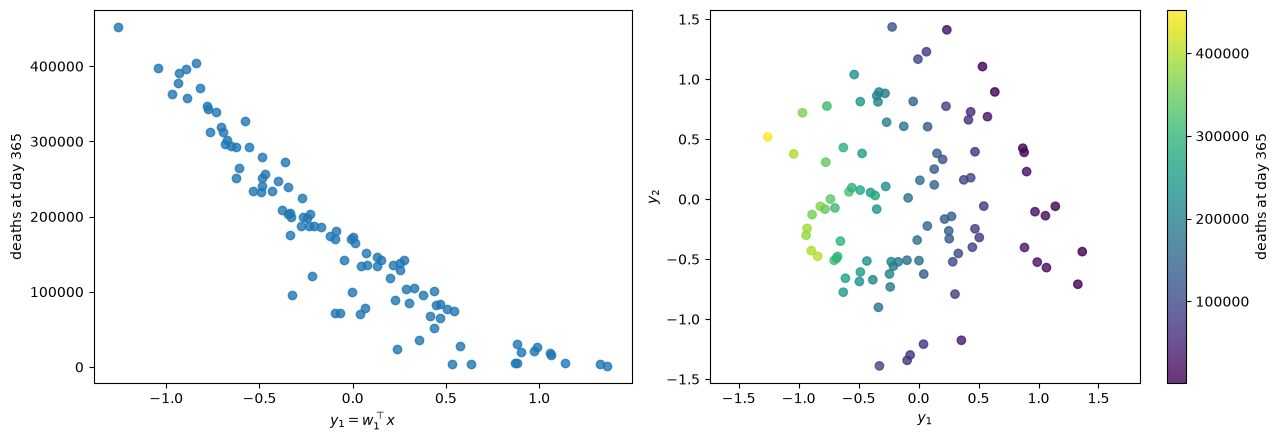

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label=qlabel, ax=axes[0])
ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, 2), X=X, f=f, dims=2, qoi_label=qlabel, ax=axes[1])
fig.tight_layout()
plt.close(fig)
Y = XN @ sub.W[:, :3]
print(f'y1 in [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}]; corr(y1, f) = {np.corrcoef(Y[:, 0], f)[0, 1]:.4f}')
fig

Deaths fall along $y_1$ (correlation $-0.9359$, $y_1$ from $-1.26$ to $1.36$), nearly linearly at first and flattening towards zero deaths at the largest $y_1$, where almost every infection is asymptomatic. The scatter about that trend is carried by $y_2$ and $y_3$; in the two-dimensional plot the colour changes mostly along $y_1$, as $\lambda_1/\lambda_2 = 9.04$ suggests.

#### Surrogates on the active variables

We fit polynomials in the first one, two and three active variables and report the leave-one-out $R^2$, as a check of the dimension.

linear, n = 1             LOO R^2 = 0.86954
quadratic, n = 1          LOO R^2 = 0.92737
quadratic, n = 2          LOO R^2 = 0.98633
quadratic, n = 3          LOO R^2 = 0.99291
cubic, n = 3              LOO R^2 = 0.99989
quadratic, all 8 inputs   LOO R^2 = 0.98867


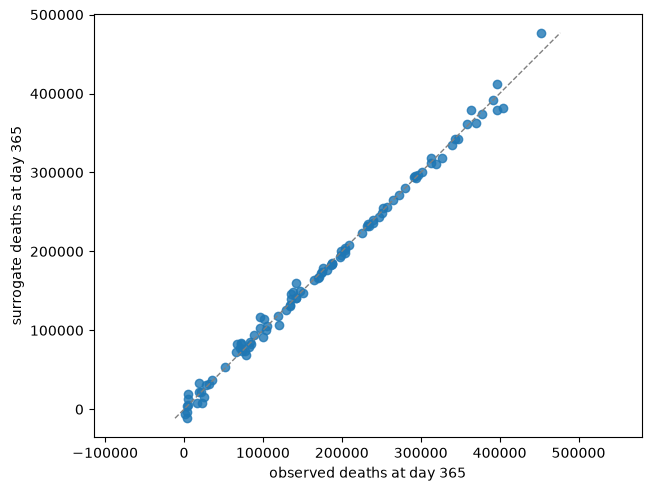

In [10]:
surs = {}
for name, k, deg in [('linear, n = 1', 1, 1), ('quadratic, n = 1', 1, 2), ('quadratic, n = 2', 2, 2),
                     ('quadratic, n = 3', 3, 2), ('cubic, n = 3', 3, 3), ('quadratic, all 8 inputs', 8, 2)]:
    s = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(sub, k), kind='poly', degree=deg)
    surs[name] = s
    print(f'{name:25s} LOO R^2 = {s.loo_r_squared:.5f}')
fig, ax = ac.plotting.plot_surrogate_fit(surs['quadratic, n = 3'], X=X, f=f, qoi_label=qlabel)
plt.close(fig)
fig

The leave-one-out $R^2$ is 0.86954 for a line and 0.92737 for a quadratic in $y_1$, 0.98633 for a quadratic in $(y_1, y_2)$, and 0.99291 for a quadratic and 0.99989 for a cubic in $(y_1, y_2, y_3)$. The cubic in three active variables (20 coefficients) beats a quadratic in all eight inputs (45 coefficients, 0.98867), which supports $n = 3$.

### Comparison with the paper

The article [[1]][R1] estimates $\mathbf C$ from a Gaussian process (GP) fitted to 2,000 random runs on $[0, 1]^8$ and shows its log eigenvalues in Fig. 5 (right, p. 25); its supplement holds that matrix (`covid_Ch.RData`). For a scale-free comparison we use eigenvalue ratios and the subspace distance $\lVert \mathbf W_{1,\mathrm{paper}}^T \mathbf W_{2}\rVert_2$, the sine of the largest principal angle, which is the article's subspace error (Eq. (7), p. 21). The article's coordinates are the unit cube, ours are $[-1, 1]$ over $[0.01, 0.99]$, so its eigenvalues correspond to ours times $0.49^2$ if the domains were equal; they are not quite (the article's design reaches $x_1 \to 0$, where the number of undetected initial infections, $233(1 - x_1)/x_1$, grows without bound).

In [11]:
print('article C (covid_Ch.RData): ln eigenvalues ' + np.array2string(np.log(paper_lam), precision=2))
print('article C: ratios lambda_k/lambda_k+1 ' + np.array2string(paper_lam[:-1] / paper_lam[1:], precision=3))
print('article C x 0.49^2: eigenvalues ' + np.array2string(paper_lam * 0.49**2, precision=3))
print('this notebook: eigenvalues ' + np.array2string(lam[:k0], precision=3))
for k in (1, 2, 3):
    d = np.linalg.norm(paper_W[:, :k].T @ sub.W[:, k:], 2)
    print(f'n = {k}: distance between the article\'s and this notebook\'s subspaces {d:.3g}')
print('this notebook / (article x 0.49^2), lambda_1..lambda_4: ' + np.array2string(lam[:4] / (paper_lam[:4] * 0.49**2), precision=3))
d3 = np.linalg.norm(paper_W.T @ sub.W[:, 3:], 2)
print(f'ln of the 3-D distance (the scale of the article\'s Fig. 6): {np.log(d3):.2f}')
print('|w_k(article) . w_k(notebook)|, k = 1..3: ' + ', '.join(f'{abs(paper_W[:, k] @ sub.W[:, k]):.4f}' for k in range(3)))

article C (covid_Ch.RData): ln eigenvalues [25.81 23.56 22.09 17.69 15.9  15.8  15.76 15.47]
article C: ratios lambda_k/lambda_k+1 [ 9.453  4.357 81.801  5.999  1.104  1.036  1.331]
article C x 0.49^2: eigenvalues [3.883e+10 4.107e+09 9.427e+08 1.152e+07 1.921e+06 1.741e+06 1.680e+06
 1.262e+06]
this notebook: eigenvalues [3.955e+10 4.376e+09 1.310e+09 3.722e+06 4.448e+04 1.349e+04]
n = 1: distance between the article's and this notebook's subspaces 0.0335
n = 2: distance between the article's and this notebook's subspaces 0.052
n = 3: distance between the article's and this notebook's subspaces 0.0152
this notebook / (article x 0.49^2), lambda_1..lambda_4: [1.019 1.065 1.389 0.323]
ln of the 3-D distance (the scale of the article's Fig. 6): -4.19
|w_k(article) . w_k(notebook)|, k = 1..3: 0.9994, 0.9985, 0.9985


| Quantity | Paper value | Notebook value |
|---|---|---|
| Number of inputs | 7 items in footnote 4 (p. 24); 8 eigenvalues in Fig. 5, right (p. 25) | 8 (the arguments of `covid_sim`) |
| Input ranges | not reported (supplement code: $[0, 1]^8$ for the reference fit, $[0.01, 0.99]^8$ for Fig. 6) | $[0.01, 0.99]^8$ |
| Estimate of $\mathbf C$ | GP fitted to 2,000 random runs (p. 24; Fig. 5 caption) | gradient average, $M = 100$, forward differences (900 runs) |
| $\ln\lambda_1..\ln\lambda_8$ | Fig. 5, right; supplement matrix: 25.81, 23.56, 22.09, 17.69, 15.90, 15.80, 15.76, 15.47 | eigenvalues $3.955\times10^{10}$, $4.376\times10^{9}$, $1.310\times10^{9}$, $3.72\times10^{6}$, $4.45\times10^{4}$, $1.35\times10^{4}$, two at rounding level (null space of $x_4, x_5$) |
| $\lambda_1..\lambda_4$ relative to the article's $\times 0.49^2$ | — | 1.02, 1.07, 1.39, 0.323 |
| $\lambda_1/\lambda_2$, $\lambda_2/\lambda_3$, $\lambda_3/\lambda_4$ | 9.45, 4.36, 81.8 (supplement matrix) | 9.04, 3.34, 352 |
| Active subspace dimension | 3 (p. 24; Fig. 5 caption, p. 25) | 3 |
| Leading eigenvectors | not reported (supplement matrix: in the span of $x_6, x_7, x_8$) | in the span of $x_6, x_7, x_8$; $\lvert\mathbf w_k\cdot\mathbf w_{k,\mathrm{paper}}\rvert$ = 0.9994, 0.9985, 0.9985 |
| Distance to the article's 3-D subspace (Eq. (7), p. 21) | natural log of the final error of its sequential designs after 100 runs without gradients: about $-3$ to $-1.5$, medians about $-2.0$ to $-2.3$ (Fig. 6, right, p. 26; the left panel is in $\log_{10}$) | 0.0152 (ln: $-4.19$) |

The gradient-based estimate and the article's GP estimate agree on the dimension and on the three leading directions. After the change of scale by $0.49^2$, $\lambda_1$ and $\lambda_2$ agree to within 7 % and $\lambda_3$ is 39 % larger here. The small eigenvalues differ: our $\lambda_4$ is 0.323 of the article's, and its last four eigenvalues sit together on a floor (ratios 1.10, 1.04, 1.33), where ours fall to $1.35\times10^{4}$ and then to the rounding-level eigenvalues of the null space of $x_4, x_5$. A likely cause is the GP's smoothing and the article's design on $[0, 1]^8$, which reaches $x_1 \to 0$, where the number of undetected initial infections grows without bound; that cause is our reading and is not checked here. Our 3-D subspace is closer to the article's reference (ln distance $-4.19$) than the final errors of its sequential designs (Fig. 6), but on a larger budget: our estimate used 900 runs (100 samples, each with 8 finite-difference runs), the sequential designs 100 runs without gradients. Fig. 6 uses two logarithms: its right panel, which we compare with, is the natural log (`covid_boxplot.R`, line 28, in the supplement); its left panel is $\log_{10}$ of the mean error (`helper/plot_func.R`, line 34), so its values must be multiplied by $\ln 10$ before a comparison with ours. The article states that the model is too imprecise for finite differences (p. 24). With this code that is not so: forward differences with step $10^{-7}$ agree with central differences to $6.1\times10^{-8}$ (`check_accuracy.py`).

### References

[1] N. Wycoff, M. Binois, and S. M. Wild. [Sequential learning of active subspaces](https://doi.org/10.1080/10618600.2021.1874962). *Journal of Computational and Graphical Statistics*, 30(4):1224–1237, 2021. (Page numbers above are those of the author manuscript, arXiv:1907.11572v2 / HAL hal-02367750.) Supplement (appendices and `code.zip`): <https://doi.org/10.6084/m9.figshare.13611284>.

[2] E. A. Enns, M. Kirkeide, A. Mehta, R. MacLehose, G. S. Knowlton, M. K. Smith, K. M. Searle, R. Zhao, S. Gildemeister, A. Simon, E. Sanstead, and S. Kulasingam. Modeling the impact of social distancing measures on the spread of SARS-CoV-2 in Minnesota. Technical Report 1148-427724, University of Minnesota, 2020. Model code: <https://github.com/MN-COVID19-Model>.

[3] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[4] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[R1]: https://doi.org/10.1080/10618600.2021.1874962
[R2]: https://github.com/MN-COVID19-Model
[R3]: https://doi.org/10.1137/1.9781611973860
[R4]: https://doi.org/10.1016/j.ress.2017.01.013

### Acknowledgments

From [[1]][R1]: "This material was based upon work supported by the U.S. Department of Energy, Office of Science, Office of Advanced Scientific Computing Research, applied mathematics and SciDAC programs under Contract No. DE-AC02-06CH11357."

In [12]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 4.8 s
